<a href="https://colab.research.google.com/github/ClassNeuralNetwork/Skin-Disease-Dataset/blob/main/projeto_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
!pip install kagglehub

In [29]:
import kagglehub, os

path = kagglehub.dataset_download("pacificrm/skindiseasedataset")
print("Path:", path)

# Mostra a árvore (até 3 níveis) para ver como o dataset está organizado
for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(root) + f"/  ({len(files)} arquivos)")

Using Colab cache for faster access to the 'skindiseasedataset' dataset.
Path: /kaggle/input/skindiseasedataset
skindiseasedataset/  (1 arquivos)
  SkinDisease/  (0 arquivos)
    SkinDisease/  (0 arquivos)
      test/  (0 arquivos)
      train/  (0 arquivos)


In [30]:
import os

# Usamos a variável 'path' definida dinamicamente pelo kagglehub no passo anterior
base_dir = os.path.join(path, "SkinDisease", "SkinDisease")
train_dir = os.path.join(base_dir, "train")
test_dir  = os.path.join(base_dir, "test")

print("Diretório de Treino:", train_dir)
print("Existe?", os.path.exists(train_dir))
print(sorted(os.listdir(train_dir)))

print("\nDiretório de Teste:", test_dir)
print("Existe?", os.path.exists(test_dir))
print(sorted(os.listdir(test_dir)))

Diretório de Treino: /kaggle/input/skindiseasedataset/SkinDisease/SkinDisease/train
Existe? True
['Acne', 'Actinic_Keratosis', 'Benign_tumors', 'Bullous', 'Candidiasis', 'DrugEruption', 'Eczema', 'Infestations_Bites', 'Lichen', 'Lupus', 'Moles', 'Psoriasis', 'Rosacea', 'Seborrh_Keratoses', 'SkinCancer', 'Sun_Sunlight_Damage', 'Tinea', 'Unknown_Normal', 'Vascular_Tumors', 'Vasculitis', 'Vitiligo', 'Warts']

Diretório de Teste: /kaggle/input/skindiseasedataset/SkinDisease/SkinDisease/test
Existe? True
['Acne', 'Actinic_Keratosis', 'Benign_tumors', 'Bullous', 'Candidiasis', 'DrugEruption', 'Eczema', 'Infestations_Bites', 'Lichen', 'Lupus', 'Moles', 'Psoriasis', 'Rosacea', 'Seborrh_Keratoses', 'SkinCancer', 'Sun_Sunlight_Damage', 'Tinea', 'Unknown_Normal', 'Vascular_Tumors', 'Vasculitis', 'Vitiligo', 'Warts']


In [31]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

img_size = (224, 224)
batch_size = 32

# 1. Listar todas as classes disponíveis no diretório de treino
all_classes = sorted(os.listdir(train_dir))

# 2. Filtrar removendo a classe 'Unknown_Normal'
active_classes = [c for c in all_classes if c != 'Unknown_Normal']

# 3. Carregar os datasets especificando apenas as classes ativas
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical',
    class_names=active_classes,  # Garante a remoção da classe indesejada
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical',
    class_names=active_classes,  # Mantém a consistência no teste
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Classes Ativas ({num_classes}):", class_names)

# 4. Aplicar o pré-processamento da ResNet50
def preprocess_resnet(images, labels):
    images = tf.keras.applications.resnet50.preprocess_input(images)
    return images, labels

train_ds = train_ds.map(preprocess_resnet).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.map(preprocess_resnet).prefetch(buffer_size=tf.data.AUTOTUNE)

Found 12247 files belonging to 21 classes.
Found 1357 files belonging to 21 classes.
Classes Ativas (21): ['Acne', 'Actinic_Keratosis', 'Benign_tumors', 'Bullous', 'Candidiasis', 'DrugEruption', 'Eczema', 'Infestations_Bites', 'Lichen', 'Lupus', 'Moles', 'Psoriasis', 'Rosacea', 'Seborrh_Keratoses', 'SkinCancer', 'Sun_Sunlight_Damage', 'Tinea', 'Vascular_Tumors', 'Vasculitis', 'Vitiligo', 'Warts']


In [32]:
import os

extensoes_validas = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

print("--- CONTAGEM NO DIRETÓRIO DE TREINO (Classes Ativas) ---")
for classe in active_classes:
    pasta = os.path.join(train_dir, classe)

    if os.path.isdir(pasta):
        arquivos = os.listdir(pasta)

        imagens = [
            f for f in arquivos
            if f.lower().endswith(extensoes_validas)
            and os.path.isfile(os.path.join(pasta, f))
        ]

        outros = len(arquivos) - len(imagens)

        print(f"Classe: {classe}")
        print(f"  Total de imagens: {len(imagens)}")
        print(f"  Outros arquivos: {outros}")

--- CONTAGEM NO DIRETÓRIO DE TREINO (Classes Ativas) ---
Classe: Acne
  Total de imagens: 593
  Outros arquivos: 0
Classe: Actinic_Keratosis
  Total de imagens: 748
  Outros arquivos: 0
Classe: Benign_tumors
  Total de imagens: 1093
  Outros arquivos: 0
Classe: Bullous
  Total de imagens: 504
  Outros arquivos: 0
Classe: Candidiasis
  Total de imagens: 248
  Outros arquivos: 0
Classe: DrugEruption
  Total de imagens: 547
  Outros arquivos: 0
Classe: Eczema
  Total de imagens: 1010
  Outros arquivos: 0
Classe: Infestations_Bites
  Total de imagens: 524
  Outros arquivos: 0
Classe: Lichen
  Total de imagens: 553
  Outros arquivos: 0
Classe: Lupus
  Total de imagens: 311
  Outros arquivos: 0
Classe: Moles
  Total de imagens: 361
  Outros arquivos: 0
Classe: Psoriasis
  Total de imagens: 820
  Outros arquivos: 0
Classe: Rosacea
  Total de imagens: 254
  Outros arquivos: 0
Classe: Seborrh_Keratoses
  Total de imagens: 455
  Outros arquivos: 0
Classe: SkinCancer
  Total de imagens: 693
  Out

In [33]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Extrair os rótulos (labels) em formato categorical (one-hot) do dataset de treino
y_train_one_hot = np.concatenate([y for x, y in train_ds], axis=0)

# Converter de one-hot encoding para índices de classe de 1D (ex: [0, 15, 3, 20...])
y_train = np.argmax(y_train_one_hot, axis=1)

# Descobre as classes únicas presentes
classes = np.unique(y_train)

# Calcula os pesos balanceados
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

# Transforma em um dicionário que o Keras aceita: {indice_da_classe: peso}
class_weights_dict = dict(zip(classes, weights))

print("Pesos calculados por classe:")
for cls_idx, weight in class_weights_dict.items():
    print(f"Classe {cls_idx} ({class_names[cls_idx]}): {weight:.4f}")

Pesos calculados por classe:
Classe 0 (Acne): 0.9835
Classe 1 (Actinic_Keratosis): 0.7797
Classe 2 (Benign_tumors): 0.5336
Classe 3 (Bullous): 1.1571
Classe 4 (Candidiasis): 2.3516
Classe 5 (DrugEruption): 1.0662
Classe 6 (Eczema): 0.5774
Classe 7 (Infestations_Bites): 1.1130
Classe 8 (Lichen): 1.0546
Classe 9 (Lupus): 1.8752
Classe 10 (Moles): 1.6155
Classe 11 (Psoriasis): 0.7112
Classe 12 (Rosacea): 2.2960
Classe 13 (Seborrh_Keratoses): 1.2817
Classe 14 (SkinCancer): 0.8415
Classe 15 (Sun_Sunlight_Damage): 1.8692
Classe 16 (Tinea): 0.6318
Classe 17 (Vascular_Tumors): 1.0740
Classe 18 (Vasculitis): 1.2651
Classe 19 (Vitiligo): 0.8168
Classe 20 (Warts): 1.0055


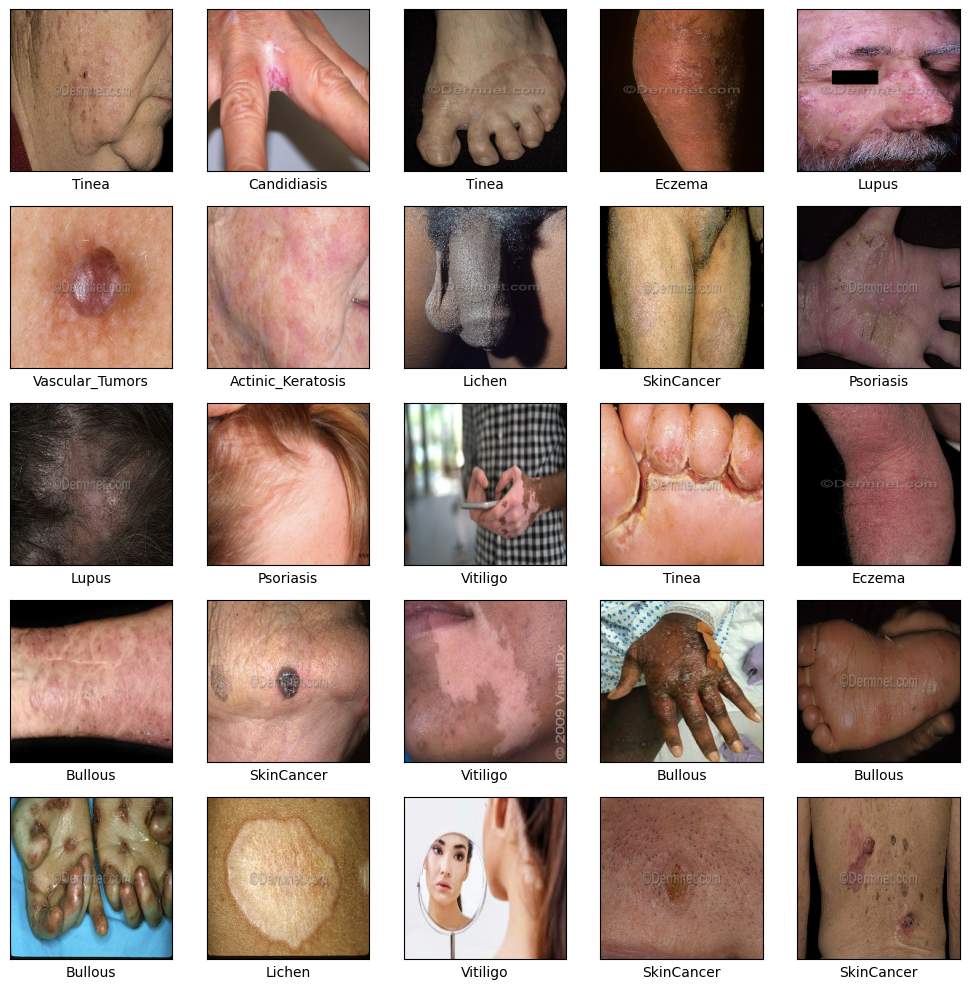

In [34]:
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        # Desfazer o pré-processamento da ResNet apenas para exibir na tela
        img = images[i].numpy() + [103.939, 116.779, 123.68]
        img = img[..., ::-1]
        img = np.clip(img / 255.0, 0, 1)

        plt.imshow(img)
        plt.xlabel(class_names[np.argmax(labels[i])])
    plt.tight_layout()
    plt.show()
    break


In [35]:
#Resnet50
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, UpSampling2D
from tensorflow.keras.models import Model

# Definir a entrada com o formato original
inputs = Input(shape=(224, 224, 3)) # Note que o seu dataset já carrega em 224x224, não precisamos do UpSampling2D(32x32)

# Carregar a ResNet50 sem a camada de classificação do ImageNet
base_model = ResNet50(weights='imagenet', include_top=False, input_tensor=inputs)

# Descongelar as camadas superiores do modelo base para o Fine-Tuning
base_model.trainable = True

# Número de camadas a congelar
fine_tune_at = 140
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Adicionar novas camadas de classificação no topo
x = base_model.output
x = GlobalAveragePooling2D(name='fine_tuning_avg_pool')(x)
x = Dense(256, activation='relu', name='fine_tuning_dense')(x)
# Usar a variável dinâmica 'num_classes' que agora é 21
predictions = Dense(num_classes, activation='softmax', name='fine_tuning_predictions')(x)

# Instanciar o modelo final
model_fine_tuning = Model(inputs=inputs, outputs=predictions)

# Compilar o modelo com uma taxa de aprendizado baixa
model_fine_tuning.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_fine_tuning.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,117,653 (92.00 MB)

 Trainable params: 15,507,989 (59.16 MB)

 Non-trainable params: 8,609,664 (32.84 MB)

In [36]:
# Definir o callback EarlyStopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Executar o treinamento passando o callback
history_fine_tuning = model_fine_tuning.fit(
    train_ds,
    epochs=100,  # Aumentamos as épocas pois o EarlyStopping interromperá se necessário
    validation_data=test_ds,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
)

Epoch 1/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 96s 199ms/step - accuracy: 0.2023 - loss: 2.6969 - val_accuracy: 0.3147 - val_loss: 2.2814
Epoch 2/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 63s 163ms/step - accuracy: 0.4133 - loss: 1.9487 - val_accuracy: 0.4016 - val_loss: 1.9515
Epoch 3/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 62s 160ms/step - accuracy: 0.5330 - loss: 1.5362 - val_accuracy: 0.4569 - val_loss: 1.7622
Epoch 4/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 62s 161ms/step - accuracy: 0.6320 - loss: 1.2282 - val_accuracy: 0.5004 - val_loss: 1.6277
Epoch 5/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 62s 160ms/step - accuracy: 0.7160 - loss: 0.9736 - val_accuracy: 0.5365 - val_loss: 1.5278
Epoch 6/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 83s 162ms/step - accuracy: 0.7844 - loss: 0.7634 - val_accuracy: 0.5623 - val_loss: 1.4556
Epoch 7/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 81s 162ms/step - accuracy: 0.8485 - loss: 0.5852 - val_accuracy: 0.5917 - val_loss: 1.3979
Epoch 8/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 62s 161ms/step - accuracy: 0.8963 -

In [37]:

test_loss, test_accuracy = model_fine_tuning.evaluate(test_ds)

print(f"\nPerda no teste: {test_loss:.4f}")
print(f"Acurácia no teste: {test_accuracy * 100:.2f}%")

43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - accuracy: 0.6212 - loss: 1.3479

Perda no teste: 1.3479
Acurácia no teste: 62.12%


In [38]:
from sklearn.metrics import classification_report
import numpy as np

# Obter as classes reais (one-hot) do dataset de teste
y_true_one_hot = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Converter de one-hot para classes 1D
y_true = np.argmax(y_true_one_hot, axis=1)

# Usar o nome correto do modelo: model_fine_tuning
y_prob = model_fine_tuning.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

43/43 ━━━━━━━━━━━━━━━━━━━━ 13s 210ms/step
                     precision    recall  f1-score   support

               Acne     0.7746    0.8462    0.8088        65
  Actinic_Keratosis     0.6413    0.7108    0.6743        83
      Benign_tumors     0.5635    0.5868    0.5749       121
            Bullous     0.6275    0.5818    0.6038        55
        Candidiasis     0.5769    0.5556    0.5660        27
       DrugEruption     0.5588    0.6230    0.5891        61
             Eczema     0.5630    0.6786    0.6154       112
 Infestations_Bites     0.4833    0.4833    0.4833        60
             Lichen     0.6250    0.4918    0.5505        61
              Lupus     0.4583    0.3235    0.3793        34
              Moles     0.5405    0.5000    0.5195        40
          Psoriasis     0.6452    0.6818    0.6630        88
            Rosacea     0.7241    0.7500    0.7368        28
  Seborrh_Keratoses     0.5926    0.6275    0.6095        51
         SkinCancer     0.5897    0.5974  

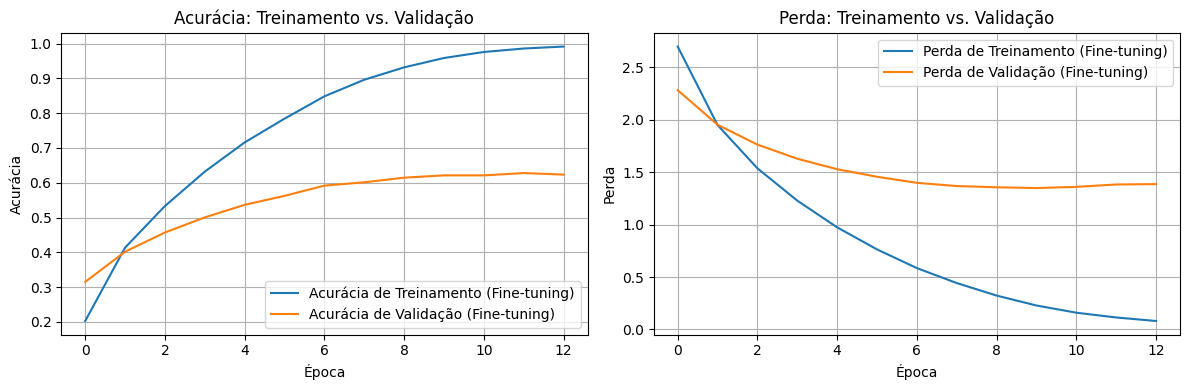

In [39]:
# Gráficos de treinamento
plt.figure(figsize=(12, 4))

# Gráfico de acurácia
plt.subplot(1, 2, 1)

plt.plot(
    history_fine_tuning.history['accuracy'],
    label='Acurácia de Treinamento (Fine-tuning)'
)

plt.plot(
    history_fine_tuning.history['val_accuracy'],
    label='Acurácia de Validação (Fine-tuning)'
)

plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.title('Acurácia: Treinamento vs. Validação')
plt.legend()
plt.grid(True)

# Gráfico de perda
plt.subplot(1, 2, 2)

plt.plot(
    history_fine_tuning.history['loss'],
    label='Perda de Treinamento (Fine-tuning)'
)

plt.plot(
    history_fine_tuning.history['val_loss'],
    label='Perda de Validação (Fine-tuning)'
)

plt.xlabel('Época')
plt.ylabel('Perda')
plt.title('Perda: Treinamento vs. Validação')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


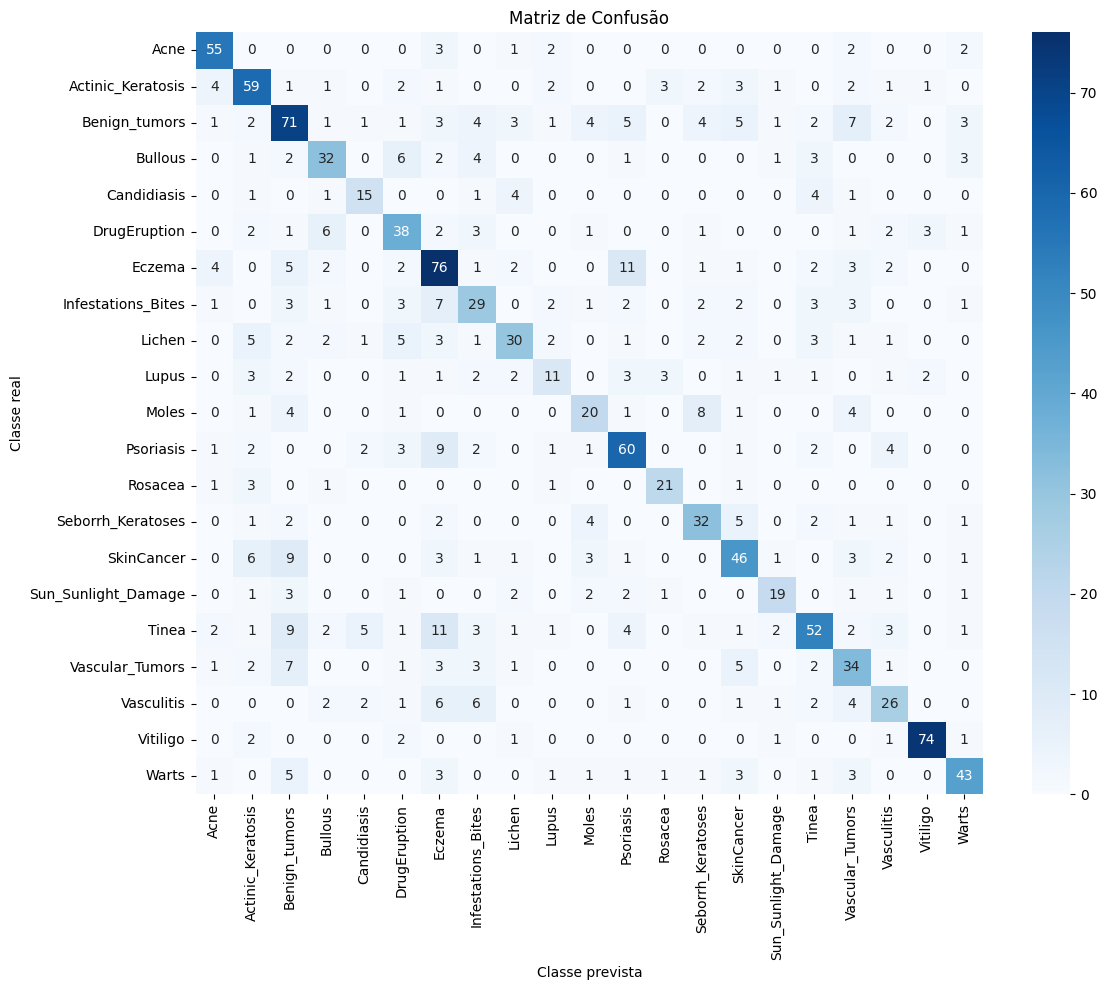

In [40]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Obter as classes reais (one-hot) do dataset de teste
y_true_one_hot = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# 2. Converter de one-hot para classes 1D
y_true = np.argmax(y_true_one_hot, axis=1)

# 3. Usar o nome correto do modelo: model_fine_tuning
y_prob = model_fine_tuning.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# 4. Calcular a matriz de confusão
cm = confusion_matrix(y_true, y_pred)

# 5. Plotar a matriz de confusão
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matriz de Confusão")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

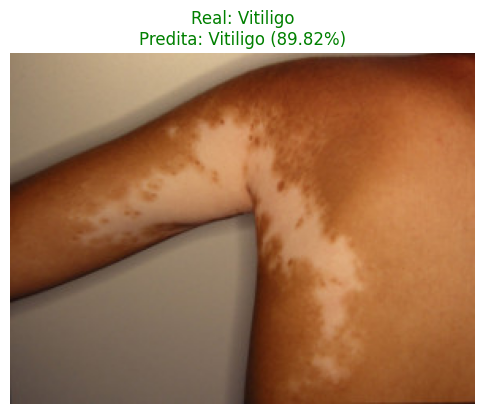

Arquivo: vitiligo-32__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd.jpeg
Classe real: Vitiligo
Classe prevista: Vitiligo
Confiança: 89.82%
Resultado: ACERTOU

Probabilidades por classe:
Acne: 0.04%
Actinic_Keratosis: 0.35%
Benign_tumors: 0.06%
Bullous: 0.07%
Candidiasis: 0.10%
DrugEruption: 5.51%
Eczema: 0.01%
Infestations_Bites: 1.28%
Lichen: 0.75%
Lupus: 0.41%
Moles: 0.02%
Psoriasis: 0.01%
Rosacea: 0.01%
Seborrh_Keratoses: 0.01%
SkinCancer: 0.40%
Sun_Sunlight_Damage: 0.85%
Tinea: 0.00%
Vascular_Tumors: 0.05%
Vasculitis: 0.25%
Vitiligo: 89.82%
Warts: 0.00%


In [41]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array

# Garantir que as class_names estejam atualizadas com as 21 classes do dataset atual
class_names = active_classes

# Escolhemos uma classe existente no seu diretório de testes para testar
classe = "Vitiligo"
pasta = os.path.join(test_dir, classe)

arquivos = [
    nome for nome in os.listdir(pasta)
    if nome.lower().endswith((".jpg", ".jpeg", ".png"))
]

if not arquivos:
    raise ValueError(f"Nenhuma imagem encontrada na pasta: {pasta}")

nome_imagem = random.choice(arquivos)
caminho_imagem = os.path.join(pasta, nome_imagem)

# Carregar a imagem no tamanho esperado pelo seu modelo (224, 224)
img = load_img(
    caminho_imagem,
    target_size=(224, 224),
    color_mode="rgb"
)
img_array = img_to_array(img)

# Expandir dimensões e aplicar o pré-processamento específico da ResNet50
entrada = np.expand_dims(img_array, axis=0)
entrada = tf.keras.applications.resnet50.preprocess_input(entrada)

# Fazer a predição usando o modelo correto: model_fine_tuning
predicao = model_fine_tuning.predict(entrada, verbose=0)[0]

indice_predito = np.argmax(predicao)
classe_predita = class_names[indice_predito]
confianca = predicao[indice_predito] * 100

plt.figure(figsize=(6, 6))
plt.imshow(load_img(caminho_imagem))
plt.axis("off")
plt.title(
    f"Real: {classe}\n"
    f"Predita: {classe_predita} ({confianca:.2f}%)",
    color="green" if classe == classe_predita else "red"
)
plt.show()

print("Arquivo:", nome_imagem)
print("Classe real:", classe)
print("Classe prevista:", classe_predita)
print(f"Confiança: {confianca:.2f}%")
print("Resultado:", "ACERTOU" if classe == classe_predita else "ERROU")

print("\nProbabilidades por classe:")
for nome, probabilidade in zip(class_names, predicao):
    print(f"{nome}: {probabilidade * 100:.2f}%")

In [42]:
model_fine_tuning.save("modelo_SkinDisease.keras")

In [43]:
!pip install shap

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_178
Received: inputs=['Tensor(shape=(5, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_178
Received: inputs=['Tensor(shape=(50, 224, 224, 3))']
  warnings.warn(msg)


Classe prevista: Acne, Classe real: Acne


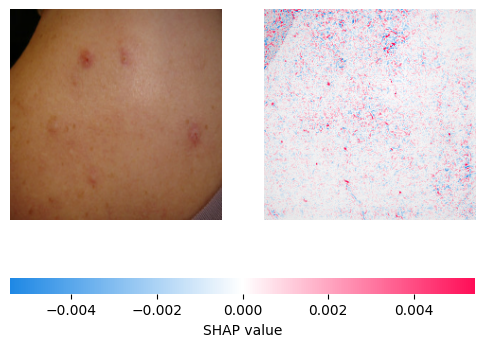

Classe prevista: Actinic_Keratosis, Classe real: Actinic_Keratosis


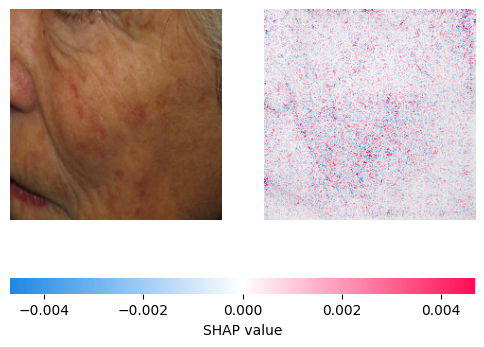

Classe prevista: Benign_tumors, Classe real: Benign_tumors


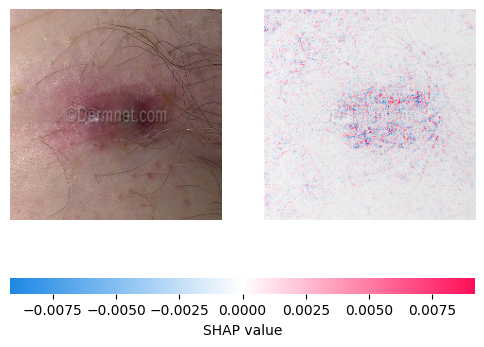

Classe prevista: Bullous, Classe real: Bullous


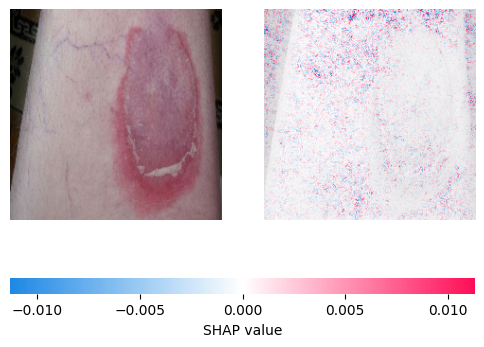

Classe prevista: Tinea, Classe real: Candidiasis


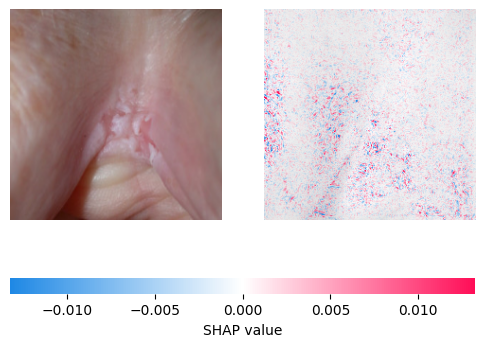

In [44]:
#SHAP

import shap
import numpy as np

background = np.concatenate(
    [x.numpy() for x, y in train_ds.take(4)],
    axis=0
)[:100]

# Uma imagem de cada uma das 5 primeiras classes encontradas no teste
amostras, rotulos, vistos = [], [], set()
for imgs, lbls in test_ds:
    for img, lbl in zip(imgs.numpy(), lbls.numpy()):
        c = int(np.argmax(lbl))
        if c not in vistos:
            vistos.add(c); amostras.append(img); rotulos.append(lbl)
        if len(vistos) == 5: break
    if len(vistos) == 5: break

test_sample = np.array(amostras)
test_labels = np.array(rotulos)

preds = model_fine_tuning.predict(test_sample, verbose=0)
pred_classes = np.argmax(preds, axis=1)
real_classes = np.argmax(test_labels, axis=1)


explainer = shap.GradientExplainer(model_fine_tuning, background)
shap_values = explainer.shap_values(test_sample)


for i in range(len(test_sample)):
    print(
        f"Classe prevista: {class_names[pred_classes[i]]}, "
        f"Classe real: {class_names[real_classes[i]]}"
    )

    if isinstance(shap_values, list):
        valores_imagem = shap_values[pred_classes[i]][i:i+1]
    else:
        valores = np.asarray(shap_values)

        if valores.ndim == 5:
            valores_imagem = valores[i:i+1, ..., pred_classes[i]]
        elif valores.ndim == 4:
            valores_imagem = valores[i:i+1]
        else:
            raise ValueError(
                f"Formato SHAP inesperado: {valores.shape}"
            )


    imagem_exibicao = test_sample[i:i+1].copy()
    imagem_exibicao += np.array([103.939, 116.779, 123.68])
    imagem_exibicao = imagem_exibicao[..., ::-1]
    imagem_exibicao = np.clip(imagem_exibicao, 0, 255).astype(np.uint8)

    shap.image_plot(
        [valores_imagem],
        imagem_exibicao
    )